# Graph-based product recommendation
**Evaluated version (NetworkX / Louvain / Leiden + Neo4j GDS)** — train/test split by invoice, edge similarity, offline metrics, graph database replication and a model export for a FastAPI demo.

**Dataset:** the UCI *Online Retail* file must be downloaded to `data/Online_Retail.xlsx`; see the root README.

**Reproducibility:** notebook outputs are removed from this public version and need to be regenerated.


# Prueba 6 
## Recomendador de productos con teoría de grafos
**Datos:** `data/Online_Retail.xlsx` (ver `data/README.md`).


El objetivo es conseguir recomendar productos más atractivos para el cliente. La idea es que dos productos que aparecen juntos en muchas facturas están relacionados. Proyectamos las facturas
en un grafo de productos, detectamos comunidades (**Louvain**, refinadas con **Leiden**) y recomendamos dentro
de cada comunidad. Validamos con un *holdout* de facturas frente a un *baseline*.

---
## *1. Construcción del dataset*

In [1]:
# Run from the repository root so `data/` and `artifacts/` resolve correctly,
# whether Jupyter was opened from the root or from `notebooks/`.
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

In [2]:
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from itertools import combinations
from collections import Counter
import igraph as ig, leidenalg as la

SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'font.family': 'DejaVu Sans',
                     'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_excel('data/Online_Retail.xlsx')
df['InvoiceNo']  = df['InvoiceNo'].astype(str)
df['StockCode']  = df['StockCode'].astype(str).str.strip().str.upper()
df['Description'] = df['Description'].str.strip().str.upper()
df['is_cancel']  = df['InvoiceNo'].str.startswith('C')   # las facturas C... son cancelaciones

print(f'{df.shape[0]:,} filas x {df.shape[1]} columnas . duplicados: {df.duplicated().sum():,}')
print(f'Rango temporal: {df.InvoiceDate.min():%Y-%m-%d} -> {df.InvoiceDate.max():%Y-%m-%d}')
df.head(3)

541,909 filas x 9 columnas . duplicados: 5,268
Rango temporal: 2010-12-01 -> 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,is_cancel
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False


---
## *2. Analítica descriptiva (EDA)*


Exploramos los datos **antes** de limpiar. Cada gráfico justifica una decisión de la fase de limpieza.

### 2.1 Calidad de los datos

                       tipo  nulos_%  unicos
InvoiceNo               str      0.0   25900
StockCode               str      0.0    3958
Description          object      0.3    4193
Quantity              int64      0.0     722
InvoiceDate  datetime64[us]      0.0   23260
UnitPrice           float64      0.0    1630
CustomerID          float64     24.9    4372
Country                 str      0.0      38
is_cancel              bool      0.0       2


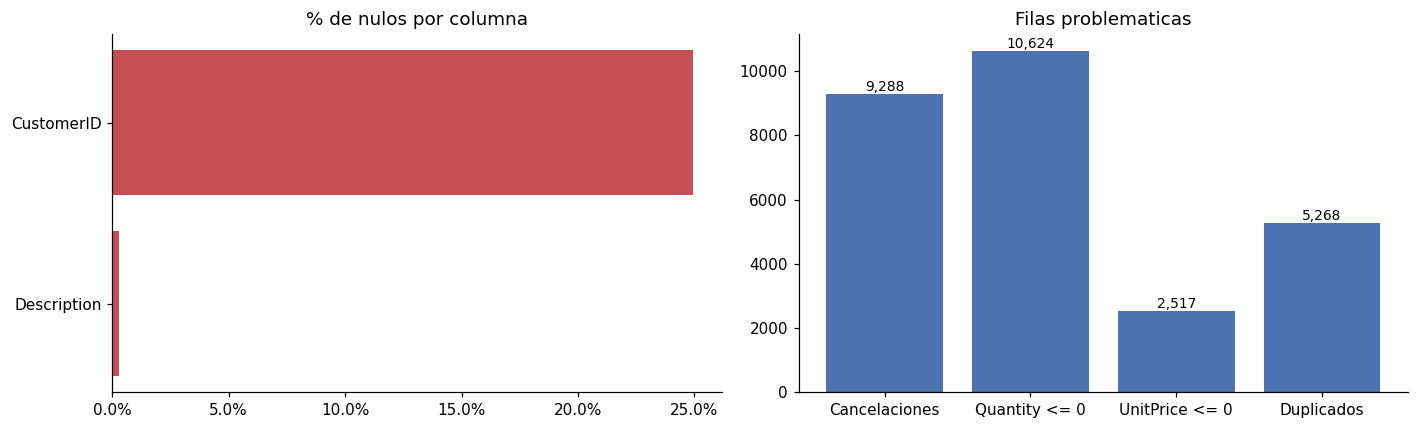

In [3]:
resumen = pd.DataFrame({'tipo': df.dtypes.astype(str),
                        'nulos_%': (df.isnull().mean()*100).round(1),
                        'unicos': df.nunique()})
print(resumen.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
nulos = (df.isnull().mean()*100)
nulos = nulos[nulos > 0].sort_values()
ax[0].barh(nulos.index, nulos.values, color='#C44E52')
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter())
ax[0].set_title('% de nulos por columna')

probs = {'Cancelaciones': df.is_cancel.sum(), 'Quantity <= 0': (df.Quantity <= 0).sum(),
         'UnitPrice <= 0': (df.UnitPrice <= 0).sum(), 'Duplicados': df.duplicated().sum()}
ax[1].bar(probs.keys(), probs.values(), color='#4C72B0')
ax[1].set_title('Filas problematicas')
for i, v in enumerate(probs.values()):
    ax[1].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

`CustomerID` tiene muchos nulos pero no lo usamos (trabajamos con facturas, no clientes). Cancelaciones, cantidades y precios ≤ 0 son las filas a eliminar.

### 2.2 Distribución de Quantity y UnitPrice

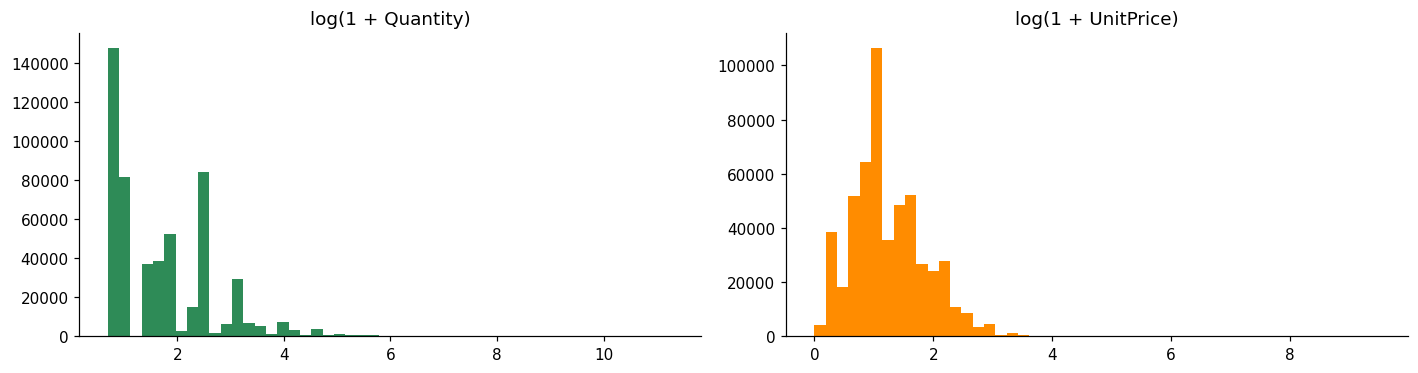

In [4]:
pos = df[(df.Quantity > 0) & (df.UnitPrice > 0)]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(np.log1p(pos.Quantity), bins=50, color='seagreen');  ax[0].set_title('log(1 + Quantity)')
ax[1].hist(np.log1p(pos.UnitPrice), bins=50, color='darkorange'); ax[1].set_title('log(1 + UnitPrice)')
plt.tight_layout(); plt.show()

Ambas están muy sesgadas por outliers (devoluciones, ajustes). Para el grafo solo importa *qué* productos coinciden en una factura, no la cantidad, así que estas colas no nos afectan una vez filtrados los valores no positivos.

### 2.3 Análisis temporal

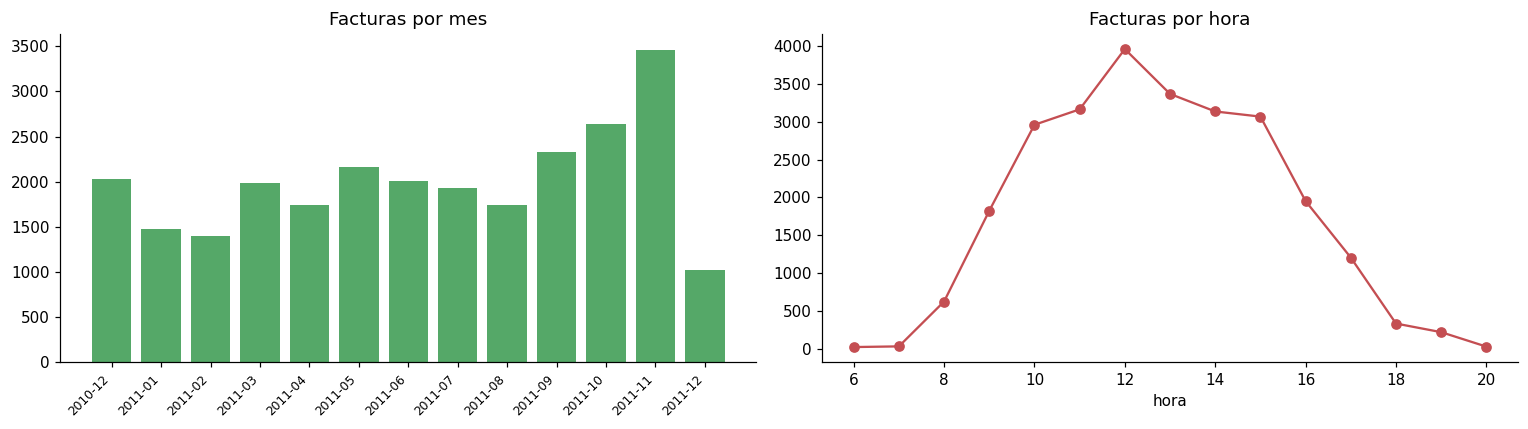

In [5]:
tmp = df.copy()
tmp['month'] = tmp.InvoiceDate.dt.to_period('M')
tmp['hour']  = tmp.InvoiceDate.dt.hour
mensual = tmp.groupby('month')['InvoiceNo'].nunique()
horaria = tmp.groupby('hour')['InvoiceNo'].nunique()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(len(mensual)), mensual.values, color='#55A868')
ax[0].set_xticks(range(len(mensual)))
ax[0].set_xticklabels([str(p) for p in mensual.index], rotation=45, ha='right', fontsize=8)
ax[0].set_title('Facturas por mes')
ax[1].plot(horaria.index, horaria.values, marker='o', color='#C44E52')
ax[1].set_title('Facturas por hora'); ax[1].set_xlabel('hora')
plt.tight_layout(); plt.show()

Se ve el pico previo a Navidad y que dic-2011 está incompleto. Un solo año de datos: es la razón por la que más adelante usamos *holdout* aleatorio y no un corte temporal (partir por fecha dejaría el pico navideño fuera del entrenamiento).

### 2.4 Concentración del negocio

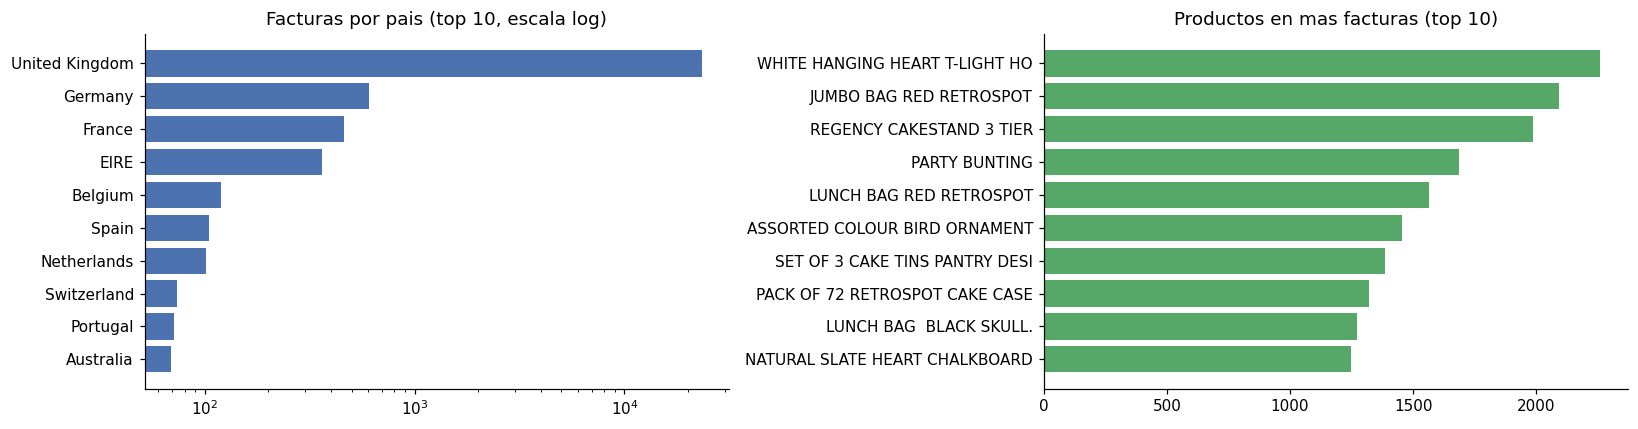

Reino Unido concentra el 90.7% de las facturas.


In [6]:
paises   = df.groupby('Country')['InvoiceNo'].nunique().sort_values().tail(10)
top_prod = df[~df.is_cancel].groupby('Description')['InvoiceNo'].nunique().sort_values().tail(10)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].barh(paises.index, paises.values, color='#4C72B0'); ax[0].set_xscale('log')
ax[0].set_title('Facturas por pais (top 10, escala log)')
ax[1].barh([d[:30] for d in top_prod.index], top_prod.values, color='#55A868')
ax[1].set_title('Productos en mas facturas (top 10)')
plt.tight_layout(); plt.show()
print(f'Reino Unido concentra el {paises.iloc[-1]/df.InvoiceNo.nunique()*100:.1f}% de las facturas.')

El negocio es casi todo Reino Unido: el grafo describe hábitos de compra británicos. Los productos más frecuentes son artículos genéricos que saldrán en muchas facturas — de ahí el *problema de la leche* que corregiremos con Jaccard/Lift.

### 2.5 Tamaño de la cesta

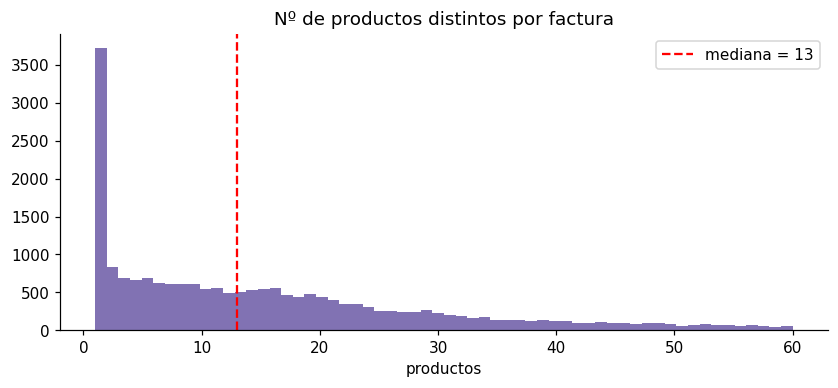

Cestas de 1 producto  : 16.9%  (no generan pareja -> fuera)
Cestas de >30 productos: 20.8%  (pedidos mayoristas -> fuera)


In [7]:
cesta = df[~df.is_cancel].groupby('InvoiceNo')['StockCode'].nunique()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(cesta[cesta <= 60], bins=60, color='#8172B3')
ax.axvline(cesta.median(), color='red', ls='--', label=f'mediana = {cesta.median():.0f}')
ax.set_title('Nº de productos distintos por factura'); ax.set_xlabel('productos'); ax.legend()
plt.show()
print(f'Cestas de 1 producto  : {(cesta==1).mean()*100:4.1f}%  (no generan pareja -> fuera)')
print(f'Cestas de >30 productos: {(cesta>30).mean()*100:4.1f}%  (pedidos mayoristas -> fuera)')

Esta distribución fija dos decisiones del preprocesado: descartar cestas de **1 producto** (no aportan aristas) y las de **>30** (mayoristas que reponen catálogo entero y meterían miles de aristas espurias).

---
## *3. Limpieza de datos*

In [8]:
# Un codigo de producto real = 5 digitos + letras opcionales (85123A, 71053, 15056BL...)
es_producto = df['StockCode'].str.match(r'^\d{5}[A-Z]*$')
print('Codigos NO producto que se descartan:')
print(df.loc[~es_producto, 'StockCode'].value_counts().head(8).to_dict())

Codigos NO producto que se descartan:
{'POST': 1256, 'DOT': 710, 'M': 572, 'C2': 144, 'D': 77, 'S': 63, 'BANK CHARGES': 37, 'AMAZONFEE': 34}


In [9]:
df_clean = df[(~df.is_cancel) & (df.Quantity > 0) & (df.UnitPrice > 0) &
              es_producto & df.Description.notna()].copy()
# Un producto que aparece en varias lineas de la misma factura es un solo nodo -> deduplicamos
df_clean = df_clean.drop_duplicates(subset=['InvoiceNo', 'StockCode'])

# Diccionario codigo -> descripcion mas frecuente (para leer las recomendaciones)
desc = (df_clean.groupby(['StockCode', 'Description']).size().reset_index(name='n')
        .sort_values('n', ascending=False).drop_duplicates('StockCode')
        .set_index('StockCode')['Description'].to_dict())

print(f'Filas    : {len(df):,} -> {len(df_clean):,}  ({len(df_clean)/len(df)*100:.1f}%)')
print(f'Productos: {df_clean.StockCode.nunique():,} . Facturas: {df_clean.InvoiceNo.nunique():,}')

Filas    : 541,909 -> 517,254  (95.5%)
Productos: 3,791 . Facturas: 19,773


Usamos **`StockCode`** como identificador de nodo (no `Description`): un mismo código puede tener descripciones ligeramente distintas por erratas, pero el código es estable.

---
## *4. Preprocesado*

Transformamos la tabla en **cestas** (una por factura) y separamos train/test.

> El *split* va **aquí, antes** de construir el grafo. Si construyéramos las features (el grafo) con todos los
> datos y validáramos después, el test ya habría influido en el modelo: *data leakage*. Escondemos facturas
> **completas**, nunca líneas sueltas.

In [10]:
rng = np.random.default_rng(SEED)
inv = df_clean['InvoiceNo'].unique()
test_inv = set(rng.choice(inv, size=int(len(inv)*0.2), replace=False))
train = df_clean[~df_clean.InvoiceNo.isin(test_inv)]
test  = df_clean[ df_clean.InvoiceNo.isin(test_inv)]

def cestas(d, lo=2, hi=30):
    s = d.groupby('InvoiceNo')['StockCode'].apply(set)
    return [g for g in s if lo <= len(g) <= hi]

cestas_train = cestas(train)
cestas_test  = [g for g in test.groupby('InvoiceNo')['StockCode'].apply(set) if len(g) >= 2]
print(f'facturas train: {train.InvoiceNo.nunique():,} -> cestas utiles (2-30): {len(cestas_train):,}')
print(f'facturas test : {test.InvoiceNo.nunique():,} -> cestas utiles (>=2)  : {len(cestas_test):,}')

facturas train: 15,819 -> cestas utiles (2-30): 10,997
facturas test : 3,954 -> cestas utiles (>=2)  : 3,650


---
## *5. Feature engineering*

Aquí se fabrica el grafo y las *features* de cada arista. 

In [11]:
pair_counts, prod_counts = Counter(), Counter()
for items in cestas_train:                       # SOLO train
    for p in items:
        prod_counts[p] += 1
    for a, b in combinations(sorted(items), 2):
        pair_counts[(a, b)] += 1

N = len(cestas_train)                             # nº de facturas (para el lift)
G = nx.Graph()
for (a, b), w in pair_counts.items():
    G.add_edge(a, b, weight=w)
print(f'grafo bruto: {G.number_of_nodes():,} nodos . {G.number_of_edges():,} aristas')

grafo bruto: 3,426 nodos . 627,448 aristas


### 5.1 Features de arista: peso, Jaccard y Lift
El **peso bruto** premia a los productos genéricos que salen en todas las facturas.
Lo corregimos normalizando:
- **Jaccard** = coincidencias / (facturas de A + de B − coincidencias). De 0 a 1.
- **Lift** = veces que coinciden respecto a lo esperado por azar. >1 = asociación real.

In [12]:
for a, b, d in G.edges(data=True):
    w, na, nb = d['weight'], prod_counts[a], prod_counts[b]
    d['jaccard'] = w / (na + nb - w)
    d['lift']    = w * N / (na * nb)

# Cambia el ranking al normalizar? Top-8 por cada criterio.
e = nx.to_pandas_edgelist(G)
e['par'] = e['source'].map(desc) + '  +  ' + e['target'].map(desc)
def top8(col): return e.sort_values(col, ascending=False)['par'].head(8).tolist()
pd.DataFrame({'por peso': top8('weight'), 'por jaccard': top8('jaccard'), 'por lift': top8('lift')})

,por peso,por jaccard,por lift
0,JUMBO BAG PINK POLKADOT + JUMBO BAG RED RETR...,GREEN PENDANT TRIPLE SHELL NECKLACE + BLACK ...,GREEN DIAMANTE PEN IN GIFT BOX + LILAC DIAM...
1,ROSES REGENCY TEACUP AND SAUCER + GREEN REGE...,SILVER/M.O.P PENDANT ORBIT NECKLACE + IVORY ...,SILVER/M.O.P PENDANT ORBIT NECKLACE + IVORY ...
2,ALARM CLOCK BAKELIKE GREEN + ALARM CLOCK BAK...,GREEN PENDANT TRIPLE SHELL NECKLACE + TURQ P...,FIRE POLISHED GLASS BRACELET RED + FIRE POLI...
3,GREEN REGENCY TEACUP AND SAUCER + PINK REGEN...,GLASS BEAD HOOP NECKLACE GREEN + CRACKED GLA...,GOLD/M.O.P PENDANT ORBIT NECKLACE + MOP PEND...
4,JUMBO BAG RED RETROSPOT + JUMBO BAG VINTAGE ...,MURANO STYLE GLASS BRACELET GOLD + BLACK DIA...,MURANO STYLE GLASS BRACELET GOLD + BLACK DIA...
5,WOODEN PICTURE FRAME WHITE FINISH + WOODEN F...,ORANGE PENDANT TRIPLE SHELL NECKLAC + PAIR O...,NEW BAROQUE LARGE NECKLACE BLK/WHIT + MURANO...
6,ROSES REGENCY TEACUP AND SAUCER + PINK REGEN...,BLUE BUNNY EASTER EGG BASKET + PINK BUNNY EA...,BLACK VINT ART DEC CRYSTAL NECKLACE + WHITE ...
7,JUMBO STORAGE BAG SUKI + JUMBO BAG RED RETRO...,WHITE HYDRANGEA ART FLOWER + CREAM CLIMBING ...,GLASS BEAD HOOP EARRINGS BLACK + MURANO STYL...


El ranking por **peso** repite superventas genéricos; **Jaccard** y **Lift** sacan parejas específicas.

### 5.2 Poda
Las aristas de peso 1–2 son ruido (una coincidencia no prueba nada) y son la mayoría. Nos quedamos con
**peso ≥ 3**, lo que además da soporte mínimo al lift (evita que se dispare con pares raros).

In [13]:
print('Distribucion de pesos (bajos):')
print(pd.Series([d['weight'] for _, _, d in G.edges(data=True)]).value_counts().sort_index().head(5).to_dict())

MIN_W = 3
Gp = nx.Graph((a, b, d) for a, b, d in G.edges(data=True) if d['weight'] >= MIN_W)
print(f'\ngrafo podado: {Gp.number_of_nodes():,} nodos . {Gp.number_of_edges():,} aristas '
      f'({Gp.number_of_edges()/G.number_of_edges():.0%} de las aristas, casi todos los nodos relevantes)')

Distribucion de pesos (bajos):


{1: 418082, 2: 105131, 3: 41912, 4: 20859, 5: 12106}



grafo podado: 2,560 nodos . 104,235 aristas (17% de las aristas, casi todos los nodos relevantes)


---
## *6. Selección del modelo*

El 'modelo' tiene dos piezas que elegir: **cómo agrupar** los productos (comunidades) y **cómo ordenar** las
recomendaciones (peso / Jaccard / Lift). Aquí decidimos la primera; la segunda la comparamos en la validación.

**Louvain** da la partición base. Después refinamos las comunidades **grandes** con **Leiden**, que no sufre el
*límite de resolución* de Louvain (su tendencia a fundir grupos pequeños). Resultado: grupos más finos y coherentes.

In [14]:
def leiden(H):
    nodes = list(H.nodes())
    if H.number_of_edges() == 0:
        return [{n} for n in nodes]
    idx = {n: i for i, n in enumerate(nodes)}
    g = ig.Graph(n=len(nodes), edges=[(idx[a], idx[b]) for a, b in H.edges()])
    g.es['weight'] = [H[a][b]['weight'] for a, b in H.edges()]
    part = la.find_partition(g, la.ModularityVertexPartition, weights='weight', seed=SEED)
    return [set(nodes[i] for i in c) for c in part]

# 1) Louvain global  vs  Leiden global
louvain     = nx.community.louvain_communities(Gp, weight='weight', resolution=1.0, seed=SEED)
leiden_glob = leiden(Gp)
Q_louvain = nx.community.modularity(Gp, louvain,     weight='weight')
Q_leiden  = nx.community.modularity(Gp, leiden_glob, weight='weight')
print(f'Louvain global : {len(louvain):>3} comunidades . Q={Q_louvain:.3f}')
print(f'Leiden  global : {len(leiden_glob):>3} comunidades . Q={Q_leiden:.3f}')

# 2) Refinar con Leiden solo las comunidades grandes
UMBRAL = 60
refinada, n_grandes = [], 0
for c in louvain:
    if len(c) > UMBRAL:
        n_grandes += 1
        refinada.extend(leiden(Gp.subgraph(c)))
    else:
        refinada.append(c)
Q_refinada = nx.community.modularity(Gp, refinada, weight='weight')
print(f'\nLouvain + refinado Leiden ({n_grandes} comunidades grandes partidas):')
print(f'   {len(refinada)} comunidades . Q={Q_refinada:.3f}')
print('   (Q global algo menor porque los grupos son mas finos, pero mas especificos para recomendar)')

Louvain global :  40 comunidades . Q=0.301
Leiden  global :  37 comunidades . Q=0.301



Louvain + refinado Leiden (8 comunidades grandes partidas):
   105 comunidades . Q=0.230
   (Q global algo menor porque los grupos son mas finos, pero mas especificos para recomendar)


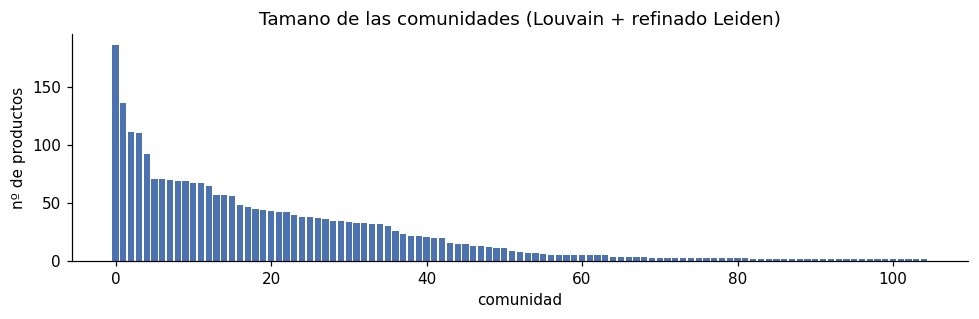

In [15]:
sizes = sorted((len(c) for c in refinada), reverse=True)
plt.figure(figsize=(9, 3))
plt.bar(range(len(sizes)), sizes, color='#4C72B0')
plt.title('Tamano de las comunidades (Louvain + refinado Leiden)')
plt.xlabel('comunidad'); plt.ylabel('nº de productos'); plt.tight_layout(); plt.show()

---
## *7. Entrenamiento*

El entrenamiento se trata de fijar el recomendador final sobre train: el índice `producto → comunidad` y la función que,
dado un producto, devuelve sus vecinos de la **misma comunidad** ordenados por la métrica elegida.

In [16]:
com = {n: i for i, c in enumerate(refinada) for n in c}   # producto -> comunidad

def recomendar(producto, metrica='jaccard', k=5):
    if producto not in Gp or producto not in com:
        return []
    c = com[producto]
    vecinos = [(v, Gp[producto][v][metrica]) for v in Gp[producto] if com.get(v) == c]
    vecinos.sort(key=lambda x: -x[1])
    return [v for v, _ in vecinos[:k]]

semilla = prod_counts.most_common(1)[0][0]
print('Semilla:', desc[semilla], '\n')
for m in ['weight', 'jaccard', 'lift']:
    print(f'--- por {m} ---')
    for r in recomendar(semilla, m):
        print('  ', desc[r])

Semilla: WHITE HANGING HEART T-LIGHT HOLDER 

--- por weight ---
   RED HANGING HEART T-LIGHT HOLDER
   WOODEN PICTURE FRAME WHITE FINISH
   WOODEN FRAME ANTIQUE WHITE
   CANDLEHOLDER PINK HANGING HEART
   WOOD BLACK BOARD ANT WHITE FINISH
--- por jaccard ---
   RED HANGING HEART T-LIGHT HOLDER
   CANDLEHOLDER PINK HANGING HEART
   WOODEN PICTURE FRAME WHITE FINISH
   WOODEN FRAME ANTIQUE WHITE
   WOOD 2 DRAWER CABINET WHITE FINISH
--- por lift ---
   MIRRORED DOVE WALL DECORATION
   CANDLEHOLDER PINK HANGING HEART
   BLUE PAISLEY NOTEBOOK
   RED HANGING HEART T-LIGHT HOLDER
   GLASS STAR FROSTED T-LIGHT HOLDER


---
## *8. Validación y métricas de performance*

Para cada factura de test damos su producto más popular como semilla, pedimos 5 recomendaciones y comprobamos
cuántas estaban de verdad en el resto de la cesta (que el modelo no ha visto).

- **hit@5**: % de facturas con ≥1 acierto · **precision@5**: aciertos/5 · **recall@5**: aciertos/resto de cesta · **coverage**: % del catálogo que llega a recomendarse.
- **Baseline** = recomendar siempre los 5 más vendidos. Si el grafo no lo supera, no aporta nada.

In [17]:
# Legacy comparison preserved for historical context. This old evaluation
# skips baskets without predictions, making it optimistic. The corrected,
# coverage-aware evaluation follows in the next cell.
top5 = [p for p, _ in prod_counts.most_common(5)]
def baseline(producto, k=5): return top5[:k]

def evaluar(func, k=5):
    hit = prec = rec = 0; usadas = 0; recomendados = set()
    for cesta in cestas_test:
        pres = [p for p in cesta if p in Gp]
        if len(pres) < 2:
            continue
        semilla = max(pres, key=lambda p: prod_counts.get(p, 0))
        target  = set(pres) - {semilla}
        recs = func(semilla, k)
        if not recs:
            continue
        usadas += 1; recomendados.update(recs)
        aciertos = len(set(recs) & target)
        hit  += aciertos > 0
        prec += aciertos / k
        rec  += aciertos / len(target)
    n = usadas or 1
    return {'hit@5': hit/n, 'precision@5': prec/n, 'recall@5': rec/n,
            'coverage': len(recomendados)/Gp.number_of_nodes()}

resultados = pd.DataFrame({
    'peso'    : evaluar(lambda s, k: recomendar(s, 'weight',  k)),
    'jaccard' : evaluar(lambda s, k: recomendar(s, 'jaccard', k)),
    'lift'    : evaluar(lambda s, k: recomendar(s, 'lift',    k)),
    'baseline': evaluar(baseline),
}).T.round(3)
resultados

,hit@5,precision@5,recall@5,coverage
peso,0.475,0.162,0.076,0.281
jaccard,0.485,0.166,0.079,0.346
lift,0.385,0.125,0.067,0.430
baseline,0.107,0.027,0.005,0.002


### Evaluación corregida (comparable)
La evaluación anterior omitía las cestas en las que un método no devolvía recomendaciones, y el baseline de popularidad podía recomendar la propia semilla o productos fuera del grafo. La celda siguiente evalúa **todos los métodos sobre las mismas cestas de test**, excluye la semilla, cuenta una lista vacía como fallo y restringe el baseline al **mismo catálogo evaluable** (productos del grafo podado). Estas son las métricas de referencia del proyecto.

In [18]:
# Comparable evaluation across all methods on the same held-out baskets.
# This cell supersedes the legacy evaluation above for new experiments.
eligible_baskets = []
for basket in cestas_test:
    seen = {p for p in basket if p in Gp}
    if len(seen) >= 2:
        seed = max(seen, key=lambda p: (prod_counts.get(p, 0), p))
        eligible_baskets.append((seed, seen - {seed}))

# Same evaluable catalogue as the graph methods: only products in the pruned graph.
popular_in_graph = [code for code, _ in prod_counts.most_common() if code in Gp]

def popularity_baseline(seed, k=5):
    return [code for code in popular_in_graph if code != seed][:k]

def evaluate_comparable(method, k=5):
    if not eligible_baskets:
        return dict(hit_at_5=0, precision_at_5=0, recall_at_5=0,
                    coverage=0, evaluated_baskets=0)
    hits = precision = recall = 0.0
    recommended = set()
    for seed, targets in eligible_baskets:
        candidates = [p for p in method(seed, k) if p != seed][:k]
        predicted = set(candidates)
        recommended.update(predicted)
        n_hits = len(predicted & targets)
        hits += int(n_hits > 0)
        precision += n_hits / k
        recall += n_hits / len(targets)
    n = len(eligible_baskets)
    return dict(hit_at_5=hits/n, precision_at_5=precision/n,
                recall_at_5=recall/n,
                coverage=len(recommended)/Gp.number_of_nodes(), evaluated_baskets=n)

comparable_results = pd.DataFrame({
    name: evaluate_comparable(fn)
    for name, fn in {
        'weight': lambda s,k: recomendar(s,'weight',k),
        'jaccard': lambda s,k: recomendar(s,'jaccard',k),
        'lift': lambda s,k: recomendar(s,'lift',k),
        'popular baseline': popularity_baseline,
    }.items()
}).T
comparable_results['evaluated_baskets'] = comparable_results['evaluated_baskets'].astype(int)
comparable_results.round(3)


,hit_at_5,precision_at_5,recall_at_5,coverage,evaluated_baskets
weight,0.474,0.162,0.076,0.281,3633
jaccard,0.484,0.166,0.079,0.346,3633
lift,0.384,0.125,0.067,0.430,3633
popular baseline,0.135,0.036,0.006,0.002,3633


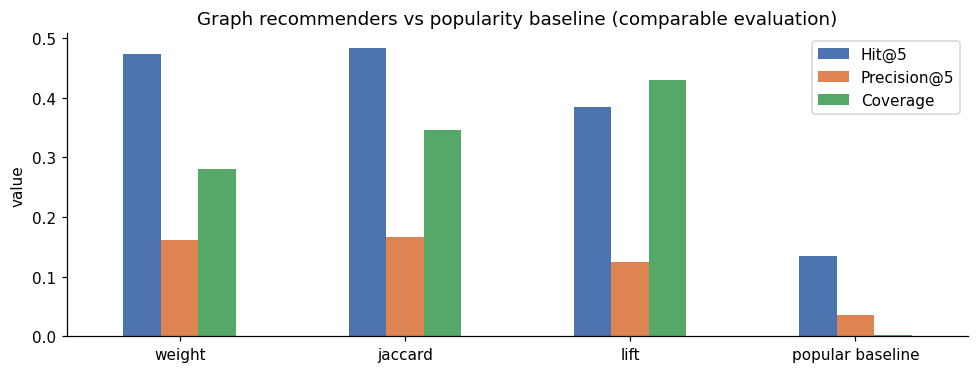

In [19]:
ax = comparable_results[['hit_at_5', 'precision_at_5', 'coverage']].plot.bar(
    figsize=(9, 3.5), rot=0, color=['#4C72B0', '#DD8452', '#55A868'])
ax.set_title('Graph recommenders vs popularity baseline (comparable evaluation)')
ax.set_ylabel('value'); ax.legend(['Hit@5', 'Precision@5', 'Coverage'])
plt.tight_layout(); plt.show()

---
## *9. Ejecutado en Neo4j*

El enunciado pide repetir el trabajo en **neo4j**, una base de datos de grafos. Aquí (1) volcamos el grafo,
(2) ejecutamos **Louvain con GDS dentro de la base de datos** y comprobamos que coincide con networkx, y
(3) mostramos que el recomendador se reduce a **una sola consulta Cypher**.

La conexión se lee de variables de entorno: así el mismo notebook vale para tu Jupyter local
(`bolt://localhost:7687`) y para el contenedor de Docker (`bolt://neo4j:7687`). Si neo4j no está levantado,
la sección se salta sola y el resto del notebook sigue funcionando.

In [20]:
import os
from neo4j import GraphDatabase

NEO4J_URI  = os.getenv('NEO4J_URI', 'bolt://localhost:7687')
NEO4J_AUTH = (os.getenv('NEO4J_USER', 'neo4j'), os.getenv('NEO4J_PASSWORD', 'CHANGE_ME_IN_ENV'))

def conectar(uri, auth):
    try:
        d = GraphDatabase.driver(uri, auth=auth, connection_timeout=5)
        d.verify_connectivity()
        print('Conectado a neo4j en', uri)
        return d
    except Exception as ex:
        print('neo4j no disponible -> se omite la seccion (levanta el contenedor y re-ejecuta).')
        print('  detalle:', type(ex).__name__)
        return None

driver = conectar(NEO4J_URI, NEO4J_AUTH)

neo4j no disponible -> se omite la seccion (levanta el contenedor y re-ejecuta).
  detalle: ServiceUnavailable


### 9.1 Meter el grafo podado en neo4j

In [21]:
def por_lotes(seq, n=5000):
    for i in range(0, len(seq), n):
        yield seq[i:i + n]

if driver:
    aristas = [{'a': a, 'b': b, 'w': d['weight']} for a, b, d in Gp.edges(data=True)]
    nombres = [{'code': c, 'desc': desc.get(c, c)} for c in Gp.nodes()]
    with driver.session() as s:
        s.run('MATCH (n) DETACH DELETE n')                      # empezar limpio
        s.run('CREATE INDEX product_code IF NOT EXISTS FOR (p:Product) ON (p.code)')
        # cargamos en lotes para no meter una transaccion gigante
        for lote in por_lotes(aristas):
            s.run('''UNWIND $rows AS r
                     MERGE (x:Product {code: r.a})
                     MERGE (y:Product {code: r.b})
                     MERGE (x)-[e:BOUGHT_WITH]-(y) SET e.weight = r.w''', rows=lote)
        s.run('UNWIND $rows AS r MATCH (p:Product {code: r.code}) SET p.desc = r.desc', rows=nombres)
        n = s.run('MATCH (p:Product) RETURN count(p) AS n').single()['n']
        m = s.run('MATCH ()-[e:BOUGHT_WITH]->() RETURN count(e) AS m').single()['m']
    print(f'Cargado en neo4j: {n:,} nodos . {m:,} relaciones')

### 9.2 Louvain en GDS

Al ejecutar Louvain en neo4j usamos la librería `GDS` (Graph Data Science) en lugar de `networkx`. Los IDs de comunidad son distintos en cada motor (etiquetas arbitrarias), así que el acuerdo se mide con **ARI** y **NMI**, que son invariantes a cómo se numeren los grupos. Cuanto más se acerquen estas métricas al valor 1, más se parecen las comunidades.

In [22]:
if driver:
    from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
    with driver.session() as s:
        try: s.run("CALL gds.graph.drop('prod', false)")   # por si ya existe de una ejecucion previa
        except Exception: pass
        s.run('''CALL gds.graph.project('prod', 'Product',
                 {BOUGHT_WITH: {orientation: 'UNDIRECTED', properties: 'weight'}})''')
        r = s.run('''CALL gds.louvain.write('prod',
                     {relationshipWeightProperty: 'weight', writeProperty: 'comunidad'})
                     YIELD communityCount, modularity
                     RETURN communityCount, modularity''').single()
        comm_neo = {row['code']: row['c'] for row in
                    s.run('MATCH (p:Product) RETURN p.code AS code, p.comunidad AS c')}
    print(f"GDS Louvain (neo4j): {r['communityCount']:>3} comunidades . Q={r['modularity']:.3f}")
    print(f'Louvain (networkx) : {len(louvain):>3} comunidades . Q={Q_louvain:.3f}')

    louv_map = {n: i for i, c in enumerate(louvain) for n in c}
    comunes = [n for n in comm_neo if n in louv_map]
    a = [louv_map[n] for n in comunes]; b = [comm_neo[n] for n in comunes]
    print(f'\nAcuerdo sobre {len(comunes):,} productos comunes:')
    print(f'   ARI = {adjusted_rand_score(a, b):.3f}   NMI = {normalized_mutual_info_score(a, b):.3f}')

Las dos implementaciones encuentran comunidades de la misma calidad (Q≈0.30) y con un acuerdo alto (ARI 0.68, NMI 0.70). Coinciden en la estructura principal; las diferencias son productos de frontera, lo normal por la parte aleatoria de Louvain. Concluimos que **las comunidades son una propiedad de los datos, no de la libreria**.

*Nota: las cifras de GDS (Q≈0.302, ARI 0.681, NMI 0.700) proceden de la ejecución original con Neo4j. En esta ejecución publicada Neo4j no estaba disponible y la sección se omite; para reproducirlas, levanta el perfil `analysis` de Docker Compose.*

### 9.3 El recomendador como una sola consulta Cypher
Toda la lógica del recomendador —vecinos del producto que estén en su misma comunidad, ordenados por peso—
cabe en una consulta que se lee casi como el enunciado. Esta es la ventaja de una base de datos de grafos.

In [23]:
if driver:
    CONSULTA = '''
    MATCH (seed:Product {code: $code})-[r:BOUGHT_WITH]-(rec:Product)
    WHERE rec.comunidad = seed.comunidad
    RETURN rec.desc AS recomendado, r.weight AS peso
    ORDER BY peso DESC LIMIT 5
    '''
    with driver.session() as s:
        filas = s.run(CONSULTA, code=semilla).data()
    print('Recomendaciones para:', desc[semilla], '\n')
    for f in filas:
        print(f"   {f['peso']:>4}  {f['recomendado']}")
    driver.close()

## Conclusiones
- **El grafo supera con claridad al baseline**: con la evaluación comparable (3.633 cestas de test), Jaccard alcanza **Hit@5 = 0,484** frente a **0,135** del baseline de popularidad restringido al mismo catálogo (~3,6×). La estructura de co-compra es real y aprovechable.
- **Jaccard ≥ peso bruto**: acierta algo más (0,484 vs 0,474) y con más *coverage* (0,35 vs 0,28): recomienda variedad, no solo superventas. **Lift** sacrifica acierto (0,384) a cambio de la mayor *coverage* (0,43): útil para descubrimiento.
- **Louvain + Leiden**: Louvain fija la partición base y refinar las comunidades grandes con Leiden las divide en grupos más específicos, lo que mantiene la recomendación dentro del mismo mundo temático.
- **neo4j confirma el resultado**: Louvain ejecutado en GDS da esencialmente la misma partición que networkx (ARI/NMI altos), y el recomendador se expresa como una única consulta Cypher. La estructura de comunidades no depende de la herramienta.
- **Limitaciones**: el *split* es aleatorio por factura (no temporal) y la evaluación es offline; no sustituye a un test A/B.

## Apéndice — Exportar el recomendador para la API (prueba)
Guarda el grafo, las comunidades, las descripciones, la popularidad y el precio típico en
`artifacts/model.json.gz` (JSON, no pickle), que la API (`api.py`) puede cargar con
`MODEL_PATH=artifacts/model.json.gz` para servir recomendaciones sin depender de neo4j.

In [24]:
import json, gzip
from pathlib import Path

edges = {}
for a, b, dd in Gp.edges(data=True):
    met = {'weight': dd['weight'], 'jaccard': dd['jaccard'], 'lift': dd['lift']}
    edges.setdefault(a, {})[b] = met
    edges.setdefault(b, {})[a] = met

pop   = dict(prod_counts)                                           # popularidad (nº de facturas)
price = df_clean.groupby('StockCode')['UnitPrice'].median().round(2).to_dict()  # precio tipico

Path('artifacts').mkdir(exist_ok=True)
with gzip.open('artifacts/model.json.gz', 'wt', encoding='utf-8') as f:
    json.dump({'edges': edges, 'com': com, 'desc': desc, 'pop': pop, 'price': price}, f, ensure_ascii=False)
print('Exported artifacts/model.json.gz with', len(edges), 'products')

Exported artifacts/model.json.gz with 2560 products
